# Imbalanced Learning — CMI Problematic Internet Use

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     cross_val_predict)
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (classification_report, precision_recall_fscore_support,
                             confusion_matrix, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score,
                             balanced_accuracy_score)

from imblearn.under_sampling import (RandomUnderSampler, EditedNearestNeighbours,
                                     CondensedNearestNeighbour)
from imblearn.over_sampling import (RandomOverSampler, SMOTE, SMOTENC,
                                    BorderlineSMOTE, ADASYN)

import warnings
warnings.filterwarnings('ignore')

SEED = 42

## Il target: da `sii` multiclasse a variabile binaria

In [2]:
df = pd.read_csv('cmi_internet_final.csv')
print(df.shape)
df['sii'].value_counts().sort_index()

(8460, 50)


sii
0    5833
1    1587
2     952
3      88
Name: count, dtype: int64

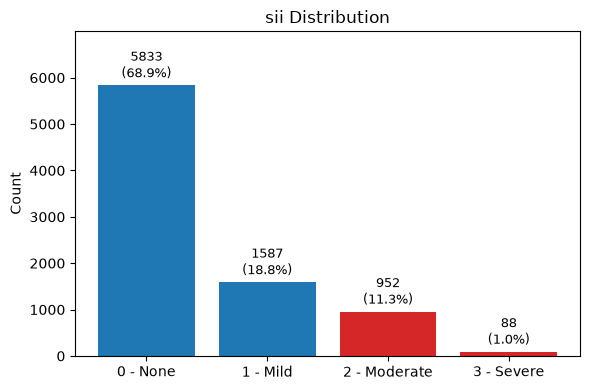

In [3]:
ctr = df['sii'].value_counts().sort_index()
labels = ['0 - None', '1 - Mild', '2 - Moderate', '3 - Severe']
total = ctr.sum()

plt.figure(figsize=(6, 4))
bars = plt.bar(labels, ctr.values, color=['tab:blue', 'tab:blue', 'tab:red', 'tab:red'])
for bar, val in zip(bars, ctr.values):
    plt.text(bar.get_x() + bar.get_width()/2, val + total*0.01,
             f'{val}\n({val/total*100:.1f}%)', ha='center', va='bottom', fontsize=9)
plt.title('sii Distribution')
plt.ylabel('Count')
plt.ylim(0, max(ctr.values)*1.2)
plt.tight_layout()
plt.show()

### Perché binarizzare, e dove tagliare

`sii` è **ordinale**: discretizza a soglie fisse il punteggio totale del questionario PCIAT
(0 = None, 0–30; 1 = Mild, 31–49; 2 = Moderate, 50–79; 3 = Severe, 80–100). Accorpare **categorie adiacenti**
quindi non distrugge la struttura del target, sposta solo la granularità della soglia. Confrontiamo i tre tagli
possibili.

In [4]:
for lbl, cond in [('{0} vs {1,2,3}', df.sii >= 1),
                  ('{0,1} vs {2,3}', df.sii >= 2),
                  ('{0,1,2} vs {3}', df.sii >= 3)]:
    yb = cond.astype(int)
    n1 = yb.sum()
    print(f'{lbl:18s}  minoranza: {n1:5d} ({100*yb.mean():5.2f}%)   '
          f'IR: {(len(yb)-n1)/n1:5.2f}:1   record minoritari nel test (20%): {int(0.2*n1)}')

{0} vs {1,2,3}      minoranza:  2627 (31.05%)   IR:  2.22:1   record minoritari nel test (20%): 525
{0,1} vs {2,3}      minoranza:  1040 (12.29%)   IR:  7.13:1   record minoritari nel test (20%): 208
{0,1,2} vs {3}      minoranza:    88 ( 1.04%)   IR: 95.14:1   record minoritari nel test (20%): 17


**Scelta: `sii ∈ {0,1}` → 0, `sii ∈ {2,3}` → 1.**

1. **Motivazione clinica.** Il taglio Mild/Moderate corrisponde al punteggio PCIAT 50, dove l'uso di internet
   diventa problematico con impatto significativo: separa i soggetti *da segnalare* da quelli *da non segnalare*.
2. **Motivazione statistica.** `sii = 3` ha solo 88 record (~17 nel test): ogni record classificato diversamente
   sposterebbe F1 di ~6 punti. Accorpando 2 e 3 si arriva a 208 record minoritari nel test.
3. **Motivazione metodologica.** `{0}` vs `{1,2,3}` (IR 2.2:1) è uno sbilanciamento troppo debole per misurare
   l'effetto delle tecniche; `{0,1,2}` vs `{3}` (IR 95:1) è troppo estremo per i dati disponibili. Il taglio scelto
   dà **IR 7.1:1**.

**Cosa si perde.** La distinzione Moderate/Severe e None/Mild, e due soggetti con punteggio 49 e 50 finiscono in
classi opposte: è il costo di ogni dicotomizzazione di una scala continua.

In [5]:
df['target'] = (df['sii'] >= 2).astype(int)

X = df.drop(columns=['id', 'sii', 'target'])
y = df['target']

print(Counter(y))
print('Imbalance ratio: %.2f : 1' % ((y == 0).sum() / (y == 1).sum()))

Counter({0: 7420, 1: 1040})
Imbalance ratio: 7.13 : 1


## Preparazione dei dati

Le 10 colonne `*-Season` sono categoriche nominali e vengono codificate con one-hot encoding. Le modalità sono note
a priori e identiche in tutto il dataset, quindi farlo prima dello split non introduce leakage.

In [6]:
season_cols = [c for c in X.columns if X[c].dtype == 'object' or str(X[c].dtype) == 'str']
print('colonne categoriche:', len(season_cols))

X = pd.get_dummies(X, columns=season_cols).astype(float)
print('shape dopo one-hot:', X.shape)

colonne categoriche: 10
shape dopo one-hot: (8460, 78)


Oltre alle one-hot, il dataset contiene altre colonne **discrete**: `Sex`, le `*_Zone`, `BIA_Frame_num`,
`BIA_Activity_Level_num` e `computerinternet_hoursday` (0–3). Le individuiamo subito (≤ 10 valori distinti)
perché servono più avanti per l'oversampling sintetico.

In [7]:
disc_cols = [c for c in X.columns if X[c].nunique() <= 10]
disc_idx = [X.columns.get_loc(c) for c in disc_cols]

print('colonne discrete:', len(disc_cols), '(di cui one-hot:',
      sum(any(c.startswith(s + '_') for s in season_cols) for c in disc_cols), ')')
print([c for c in disc_cols if not any(c.startswith(s + '_') for s in season_cols)])

colonne discrete: 51 (di cui one-hot: 40 )
['Basic_Demos-Sex', 'FGC-FGC_CU_Zone', 'FGC-FGC_GSND_Zone', 'FGC-FGC_GSD_Zone', 'FGC-FGC_PU_Zone', 'FGC-FGC_SRL_Zone', 'FGC-FGC_SRR_Zone', 'FGC-FGC_TL_Zone', 'BIA-BIA_Activity_Level_num', 'BIA-BIA_Frame_num', 'PreInt_EduHx-computerinternet_hoursday']


**Lo split precede qualsiasi ri-campionamento**: il resampling si applica solo al training set, il test resta
con la distribuzione reale. Stratifichiamo sul `sii` originale a 4 classi, così anche la proporzione della
sotto-classe più rara (`sii = 3`) resta uguale in train e test.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=df['sii'])

print('train:', X_train.shape, Counter(y_train))
print('test :', X_test.shape, Counter(y_test))

train: (6768, 78) Counter({0: 5936, 1: 832})
test : (1692, 78) Counter({0: 1484, 1: 208})


La normalizzazione è indispensabile perché ENN, CNN, SMOTE, BorderlineSMOTE e ADASYN lavorano su distanze euclidee: senza,
feature come `BIA-BIA_DEE` (ordine 10³) dominerebbero il calcolo dei vicini. Usiamo `StandardScaler`, fittato
**solo sul training set**: gli outlier estremi sono già stati trattati nel modulo di outlier detection, quindi
media e deviazione standard non ne sono distorte.

In [9]:
scaler = StandardScaler()
scaler.fit(X_train)

X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)
y_train = y_train.values
y_test = y_test.values

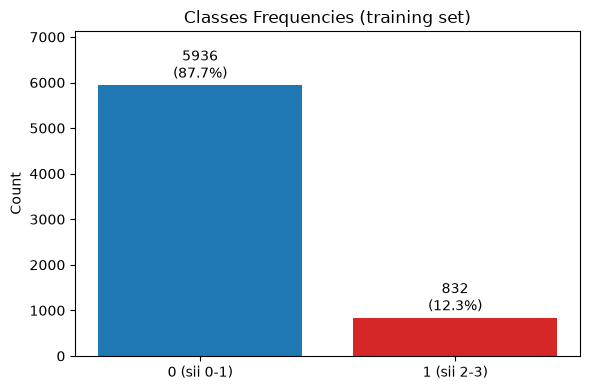

In [10]:
ctr = Counter(y_train)
labels = ['0 (sii 0-1)', '1 (sii 2-3)']
values = [ctr[0], ctr[1]]
total = sum(values)

plt.figure(figsize=(6, 4))
bars = plt.bar(labels, values, color=['tab:blue', 'tab:red'])
for bar, val in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, val + total*0.01,
             f'{val}\n({val/total*100:.1f}%)', ha='center', va='bottom')
plt.title('Classes Frequencies (training set)')
plt.ylabel('Count')
plt.ylim(0, max(values)*1.2)
plt.tight_layout()
plt.show()

## Iperparametri del Decision Tree

La grid search viene eseguita **una sola volta**, sul training set non ri-campionato, ottimizzando la ROC-AUC
(indipendente dalla soglia, quindi non premia il modello che predice sempre 0). I parametri trovati restano
**fissi per tutte le tecniche**, così le differenze osservate dipendono dal bilanciamento e non da una diversa
capacità del modello. `max_depth` è fissato a 5 per avere alberi confrontabili e leggibili.

In [11]:
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5],
    'min_samples_leaf': [1, 5, 20, 50],
    'min_samples_split': [2, 10, 50],
}

gs = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid,
                  scoring='roc_auc',
                  cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                  n_jobs=-1)
gs.fit(X_train, y_train)

BEST = gs.best_params_
print('Migliori parametri:', BEST)
print('ROC-AUC in CV: %.4f' % gs.best_score_)

Migliori parametri: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 50, 'min_samples_split': 2}
ROC-AUC in CV: 0.6680


## Funzioni di supporto

- `plot_pca`: proietta il training set ri-campionato sulle prime 2 componenti principali (PCA fittata una volta
  sola sul training originale, così i grafici sono confrontabili).
- `run_dt`: addestra il Decision Tree, valuta sul test, stampa il `classification_report` e salva le metriche
  nella tabella finale.
- `fix_discrete`: riporta al valore intero più vicino le colonne discrete dopo un oversampling sintetico (il
  motivo è spiegato nella sezione Oversampling).

Nella tabella riassuntiva teniamo precision, recall e F1 della **classe minoritaria**, più la **specificità**
(recall della classe 0), che mostra il costo pagato sulla maggioranza.

In [12]:
pca = PCA(n_components=2, random_state=SEED)
pca.fit(X_train)
print('varianza spiegata: %s (%.1f%% totale)' %
      (np.round(pca.explained_variance_ratio_, 3), 100*pca.explained_variance_ratio_.sum()))


def plot_pca(X_res, y_res, title=''):
    Z = pca.transform(X_res)
    y_res = np.asarray(y_res)
    plt.figure(figsize=(5.5, 4))
    plt.scatter(Z[y_res == 0, 0], Z[y_res == 0, 1], s=6, alpha=0.25,
                c='tab:blue', label='0 (sii 0-1)')
    plt.scatter(Z[y_res == 1, 0], Z[y_res == 1, 1], s=6, alpha=0.45,
                c='tab:red', label='1 (sii 2-3)')
    plt.title(title)
    plt.xlabel('PC1'); plt.ylabel('PC2')
    plt.legend(markerscale=2, fontsize=8)
    plt.tight_layout()
    plt.show()
    print(len(y_res), 'record nel training set')


def fix_discrete(X_res, sc):
    X_orig = sc.inverse_transform(X_res)
    X_orig[:, disc_idx] = np.round(X_orig[:, disc_idx])
    return sc.transform(X_orig)


results = []      # tabella riassuntiva
probas = {}       # probabilità predette, per le curve ROC / PR


def add_result(name, y_pred, y_prob):
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1], zero_division=0)
    results.append({
        'Metodo': name,
        'Prec': prec[1], 'Rec': rec[1], 'F1': f1[1],      # classe minoritaria
        'Spec': rec[0],                                    # recall classe 0
        'MacroF1': f1.mean(),
        'BalAcc': balanced_accuracy_score(y_test, y_pred),
        'ROC_AUC': roc_auc_score(y_test, y_prob),
        'PR_AUC': average_precision_score(y_test, y_prob),
    })


def run_dt(name, X_res, y_res, class_weight=None):
    clf = DecisionTreeClassifier(random_state=SEED, class_weight=class_weight, **BEST)
    clf.fit(X_res, y_res)

    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]
    probas[name] = y_prob

    print(classification_report(y_test, y_pred, digits=3))
    add_result(name, y_pred, y_prob)
    return clf

varianza spiegata: [0.098 0.072] (17.0% totale)


## Baseline

### Dummy classifier

Predice sempre la classe maggioritaria: accuracy 87.7% e F1 = 0 sulla minoranza. In questo contesto l'accuracy
non è una metrica utilizzabile.

In [13]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
y_pred = dummy.predict(X_test)
print(classification_report(y_test, y_pred, digits=3))

prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1], zero_division=0)
results.append({'Metodo': 'Dummy (most_frequent)', 'Prec': prec[1], 'Rec': rec[1], 'F1': f1[1],
                'Spec': rec[0], 'MacroF1': f1.mean(),
                'BalAcc': balanced_accuracy_score(y_test, y_pred),
                'ROC_AUC': 0.5, 'PR_AUC': y_test.mean()})

              precision    recall  f1-score   support

           0      0.877     1.000     0.935      1484
           1      0.000     0.000     0.000       208

    accuracy                          0.877      1692
   macro avg      0.439     0.500     0.467      1692
weighted avg      0.769     0.877     0.820      1692



### Decision Tree senza ri-bilanciamento

È il vero termine di paragone per tutte le tecniche che seguono.

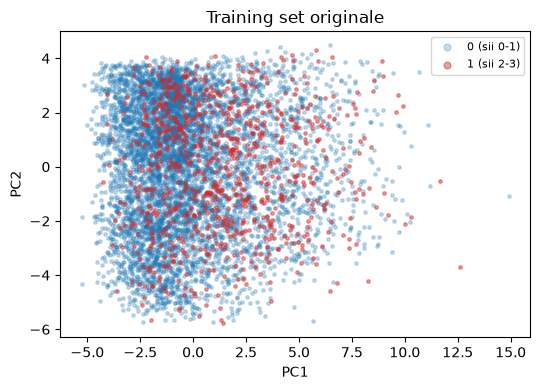

6768 record nel training set
              precision    recall  f1-score   support

           0      0.880     0.994     0.933      1484
           1      0.400     0.029     0.054       208

    accuracy                          0.875      1692
   macro avg      0.640     0.511     0.494      1692
weighted avg      0.821     0.875     0.825      1692



In [14]:
plot_pca(X_train, y_train, 'Training set originale')
clf_base = run_dt('Nessun ri-bilanciamento', X_train, y_train)

In [15]:
cm = confusion_matrix(y_test, clf_base.predict(X_test))
print(pd.DataFrame(cm, index=['reale 0', 'reale 1'], columns=['pred 0', 'pred 1']))
print('\nRecall sulla minoranza: %.3f' % (cm[1, 1] / cm[1].sum()))
print('ROC-AUC: %.3f' % roc_auc_score(y_test, clf_base.predict_proba(X_test)[:, 1]))

         pred 0  pred 1
reale 0    1475       9
reale 1     202       6

Recall sulla minoranza: 0.029
ROC-AUC: 0.696


Il modello ha un ROC-AUC discreto, quindi *ordina* i record in modo sensato, ma alla soglia standard 0.5 non
predice quasi mai la classe positiva: è il problema tipico dei dati sbilanciati.

# Undersampling

### RandomUnderSampler

Rimuove record casuali della maggioranza fino al bilanciamento completo. Semplice ma distruttivo: si buttano
circa 5100 record su 5936.

Resampled dataset shape Counter({np.int64(0): 832, np.int64(1): 832})


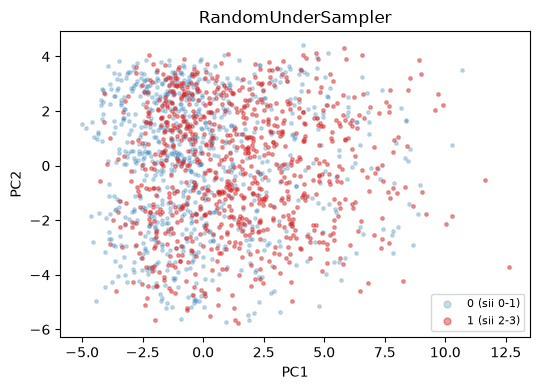

1664 record nel training set
              precision    recall  f1-score   support

           0      0.924     0.652     0.765      1484
           1      0.199     0.615     0.300       208

    accuracy                          0.648      1692
   macro avg      0.561     0.634     0.533      1692
weighted avg      0.835     0.648     0.708      1692



In [16]:
rus = RandomUnderSampler(random_state=SEED)
X_res, y_res = rus.fit_resample(X_train, y_train)
print('Resampled dataset shape %s' % Counter(y_res))

plot_pca(X_res, y_res, 'RandomUnderSampler')
run_dt('RandomUnderSampler', X_res, y_res);

### Edited Nearest Neighbours

Tecnica di *cleaning*: con le impostazioni di default rimuove un record di maggioranza se anche uno solo dei suoi
3 vicini più prossimi appartiene alla classe opposta, ripulendo la frontiera decisionale. Non punta al
bilanciamento.

> È stato provato anche **Tomek Links**, che rimuove solo le coppie di record di classe opposta mutuamente più
> vicine. Su questo dataset elimina circa 140 record di maggioranza su 5936 e il modello resta di fatto identico
> alla baseline, quindi non viene riportato.

Resampled dataset shape Counter({np.int64(0): 4550, np.int64(1): 832})


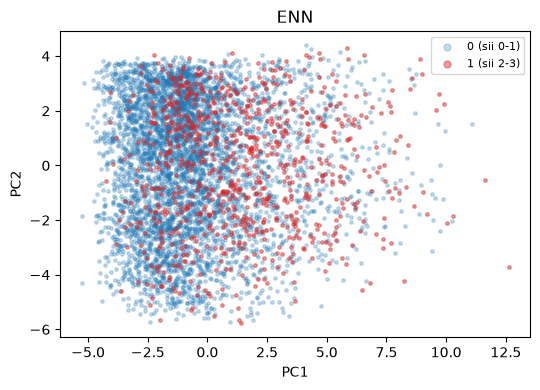

5382 record nel training set
              precision    recall  f1-score   support

           0      0.895     0.956     0.924      1484
           1      0.383     0.197     0.260       208

    accuracy                          0.862      1692
   macro avg      0.639     0.576     0.592      1692
weighted avg      0.832     0.862     0.842      1692



In [17]:
enn = EditedNearestNeighbours()
X_res, y_res = enn.fit_resample(X_train, y_train)
print('Resampled dataset shape %s' % Counter(y_res))

plot_pca(X_res, y_res, 'ENN')
run_dt('ENN', X_res, y_res);

### Condensed Nearest Neighbour

Costruisce un **sottoinsieme consistente** del training set: parte dalla minoranza (più un record di
maggioranza), scorre i restanti record di maggioranza e conserva solo quelli che un 1-NN costruito sul
sottoinsieme corrente classificherebbe male. Tiene quindi la maggioranza vicina alla frontiera e scarta il "cuore"
denso della classe. È un undersampling *informato*, ma non garantisce il bilanciamento  ed è di gran lunga il metodo
più lento del notebook.

Resampled dataset shape Counter({np.int64(0): 1650, np.int64(1): 832})


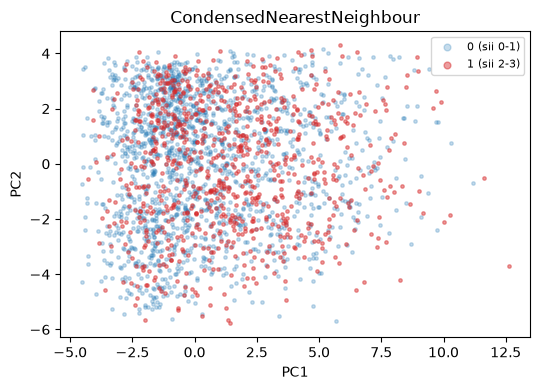

2482 record nel training set
              precision    recall  f1-score   support

           0      0.897     0.881     0.889      1484
           1      0.247     0.279     0.262       208

    accuracy                          0.807      1692
   macro avg      0.572     0.580     0.575      1692
weighted avg      0.817     0.807     0.812      1692



In [18]:
cnn = CondensedNearestNeighbour(random_state=SEED, n_jobs=-1)
X_res, y_res = cnn.fit_resample(X_train, y_train)
print('Resampled dataset shape %s' % Counter(y_res))

plot_pca(X_res, y_res, 'CondensedNearestNeighbour')
run_dt('CondensedNearestNeighbour', X_res, y_res);

# Oversampling

### RandomOverSampler

Duplica record della minoranza già esistenti. Non aggiunge informazione e favorisce l'overfitting sui duplicati;
qui l'effetto è contenuto dal vincolo `min_samples_leaf`.

Resampled dataset shape Counter({np.int64(1): 5936, np.int64(0): 5936})


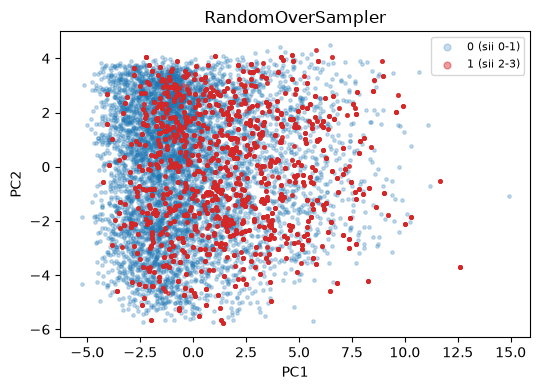

11872 record nel training set
              precision    recall  f1-score   support

           0      0.926     0.637     0.755      1484
           1      0.198     0.639     0.302       208

    accuracy                          0.637      1692
   macro avg      0.562     0.638     0.529      1692
weighted avg      0.837     0.637     0.699      1692



In [19]:
ros = RandomOverSampler(random_state=SEED)
X_res, y_res = ros.fit_resample(X_train, y_train)
print('Resampled dataset shape %s' % Counter(y_res))

plot_pca(X_res, y_res, 'RandomOverSampler')
run_dt('RandomOverSampler', X_res, y_res);

### Il problema delle colonne discrete con SMOTE

SMOTE genera ogni record sintetico per interpolazione lineare tra un record di minoranza e un suo vicino. Su una
colonna discreta il risultato è quasi sempre un valore che nei dati reali non esiste: `Sex = 0.37`,
`computerinternet_hoursday = 1.62`, una one-hot a 0.4. Questi valori compaiono **solo nei record sintetici, cioè
solo nella classe 1**, quindi l'albero può imparare a riconoscere il record sintetico invece del soggetto
problematico. Lo verifichiamo confrontando le feature più importanti della baseline e di uno SMOTE standard.

In [20]:
X_sm, y_sm = SMOTE(random_state=SEED).fit_resample(X_train, y_train)
synt = X_sm[len(y_train):]
print('record sintetici con almeno una colonna discreta non intera: %.1f%%'
      % (100 * (np.abs(fix_discrete(synt, scaler) - synt)[:, disc_idx] > 1e-6).any(axis=1).mean()))

clf_sm = DecisionTreeClassifier(random_state=SEED, **BEST).fit(X_sm, y_sm)
imp = pd.DataFrame({'Baseline': clf_base.feature_importances_,
                    'SMOTE standard': clf_sm.feature_importances_}, index=X.columns)
imp.sort_values('SMOTE standard', ascending=False).head(5).round(3)

record sintetici con almeno una colonna discreta non intera: 100.0%


,Baseline,SMOTE standard
PreInt_EduHx-computerinternet_hoursday,0.133,0.621
Basic_Demos-Sex,0.018,0.329
Basic_Demos-Age,0.006,0.041
FGC-Season_Winter,0.000,0.005
CGAS-CGAS_Score,0.083,0.002


Con SMOTE standard oltre il 90% dell'importanza si concentra su `hoursday` e `Sex`, che nella baseline pesano
molto meno: l'albero separa i valori frazionari, non la minoranza reale.

La soluzione proposta nelle slide è **SMOTENC**, che interpola solo le colonne continue e assegna a quelle
categoriche il valore **più frequente** tra i k vicini. Su questo dataset però la moda amplifica le modalità già
prevalenti nella minoranza. La cella sotto lo confronta con l'alternativa che adottiamo: SMOTE standard seguito
dall'arrotondamento delle colonne discrete al valore intero più vicino.

In [21]:
X_nc, y_nc = SMOTENC(categorical_features=disc_idx, random_state=SEED).fit_resample(X_train, y_train)
X_nc_orig = scaler.inverse_transform(X_nc[len(y_train):])
X_rd_orig = scaler.inverse_transform(fix_discrete(X_sm[len(y_train):], scaler))   # SMOTE + arrotondamento
X_tr_orig = scaler.inverse_transform(X_train)

clf_nc = DecisionTreeClassifier(random_state=SEED, **BEST).fit(X_nc, y_nc)
print('importanza di Sex: baseline %.3f | SMOTENC %.3f\n'
      % (clf_base.feature_importances_[X.columns.get_loc('Basic_Demos-Sex')],
         clf_nc.feature_importances_[X.columns.get_loc('Basic_Demos-Sex')]))

for c in ['Basic_Demos-Sex', 'BIA-BIA_Frame_num', 'PreInt_EduHx-computerinternet_hoursday']:
    j = X.columns.get_loc(c)
    print(c)
    print(pd.DataFrame({
        'maggioranza reale': pd.Series(np.round(X_tr_orig[y_train == 0, j])).value_counts(normalize=True),
        'minoranza reale': pd.Series(np.round(X_tr_orig[y_train == 1, j])).value_counts(normalize=True),
        'sintetici SMOTENC': pd.Series(np.round(X_nc_orig[:, j])).value_counts(normalize=True),
        'sintetici SMOTE arrotondato': pd.Series(np.round(X_rd_orig[:, j])).value_counts(normalize=True),
    }).sort_index().round(2), '\n')

importanza di Sex: baseline 0.018 | SMOTENC 0.198

Basic_Demos-Sex
     maggioranza reale  minoranza reale  sintetici SMOTENC  \
0.0               0.59              0.7               0.84   
1.0               0.41              0.3               0.16   

     sintetici SMOTE arrotondato  
0.0                         0.74  
1.0                         0.26   

BIA-BIA_Frame_num
     maggioranza reale  minoranza reale  sintetici SMOTENC  \
1.0               0.32             0.24               0.09   
2.0               0.61             0.68               0.90   
3.0               0.06             0.09               0.02   

     sintetici SMOTE arrotondato  
1.0                         0.21  
2.0                         0.72  
3.0                         0.07   

PreInt_EduHx-computerinternet_hoursday
     maggioranza reale  minoranza reale  sintetici SMOTENC  \
0.0               0.48             0.27               0.24   
1.0               0.20             0.18               0.21   
2.0  

SMOTENC elimina i valori frazionari ma sposta la distribuzione: i maschi (`Sex = 0`) passano dal 70% della
minoranza reale all'84% dei record sintetici, e `Frame_num = 2` dal 68% al 90%. Di conseguenza l'albero torna a
usare `Sex` come scorciatoia (importanza circa 10 volte quella della baseline), per un motivo diverso.

L'arrotondamento resta molto più vicino ai dati reali (maschi 74%, `Frame_num = 2` 72%). Per le colonne binarie e
le one-hot il record sintetico prende esattamente il valore di uno dei due record da cui è generato; per le
ordinali come `hoursday` può prendere anche un valore intermedio (tra 0 e 3 esce 1 o 2), per questo i valori
centrali risultano un po' più frequenti. Adottiamo quindi questa correzione: dopo SMOTE, BorderlineSMOTE e ADASYN
le colonne discrete vengono arrotondate con `fix_discrete` (su scala originale, poi di nuovo standardizzate).

### SMOTE (con colonne discrete arrotondate)

Resampled dataset shape Counter({np.int64(1): 5936, np.int64(0): 5936})


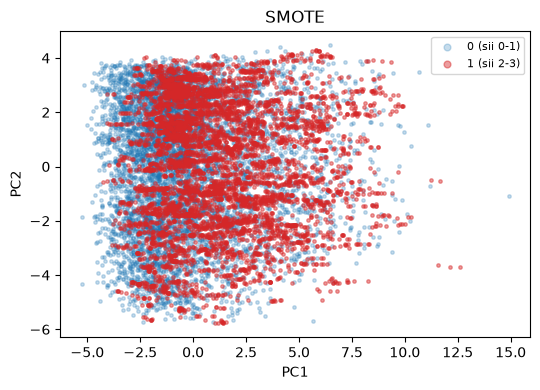

11872 record nel training set
              precision    recall  f1-score   support

           0      0.916     0.608     0.731      1484
           1      0.177     0.601     0.273       208

    accuracy                          0.607      1692
   macro avg      0.546     0.604     0.502      1692
weighted avg      0.825     0.607     0.674      1692

Feature più importanti:
Basic_Demos-Age                           0.525
FGC-FGC_PU                                0.196
PreInt_EduHx-computerinternet_hoursday    0.145
SDS-SDS_Total_Raw                         0.063
BIA-BIA_DEE                               0.017
dtype: float64


In [22]:
sm = SMOTE(random_state=SEED)
X_res, y_res = sm.fit_resample(X_train, y_train)
X_res = fix_discrete(X_res, scaler)
print('Resampled dataset shape %s' % Counter(y_res))

plot_pca(X_res, y_res, 'SMOTE')
clf_smf = run_dt('SMOTE', X_res, y_res)

print('Feature più importanti:')
print(pd.Series(clf_smf.feature_importances_, index=X.columns).sort_values(ascending=False).head(5).round(3))

### BorderlineSMOTE

Come SMOTE, ma genera record sintetici solo a partire dai record di minoranza *in zona di frontiera* (quelli con
molti vicini di maggioranza), cioè dove il classificatore sbaglia.

Resampled dataset shape Counter({np.int64(1): 5936, np.int64(0): 5936})


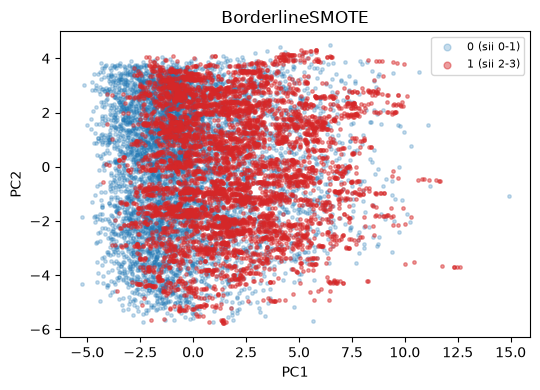

11872 record nel training set
              precision    recall  f1-score   support

           0      0.910     0.850     0.879      1484
           1      0.272     0.399     0.324       208

    accuracy                          0.795      1692
   macro avg      0.591     0.625     0.601      1692
weighted avg      0.831     0.795     0.811      1692



In [23]:
bsm = BorderlineSMOTE(random_state=SEED)
X_res, y_res = bsm.fit_resample(X_train, y_train)
X_res = fix_discrete(X_res, scaler)
print('Resampled dataset shape %s' % Counter(y_res))

plot_pca(X_res, y_res, 'BorderlineSMOTE')
run_dt('BorderlineSMOTE', X_res, y_res);

### ADASYN

Distribuzione adattiva dei record sintetici: il numero di record generati intorno a ciascun punto di minoranza è
proporzionale alla quota di maggioranza tra i suoi k vicini, quindi se ne generano di più nelle zone difficili.

Resampled dataset shape Counter({np.int64(0): 5936, np.int64(1): 5906})


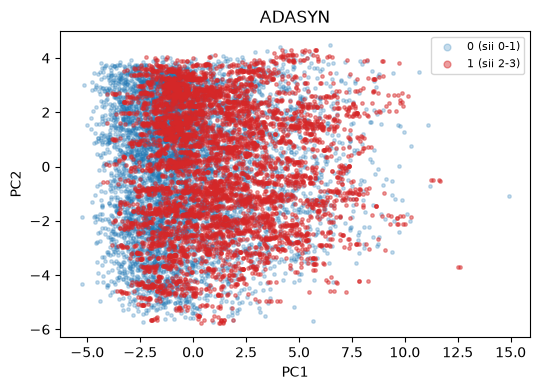

11842 record nel training set
              precision    recall  f1-score   support

           0      0.914     0.690     0.786      1484
           1      0.196     0.538     0.287       208

    accuracy                          0.671      1692
   macro avg      0.555     0.614     0.537      1692
weighted avg      0.826     0.671     0.725      1692



In [24]:
ada = ADASYN(random_state=SEED)
X_res, y_res = ada.fit_resample(X_train, y_train)
X_res = fix_discrete(X_res, scaler)
print('Resampled dataset shape %s' % Counter(y_res))

plot_pca(X_res, y_res, 'ADASYN')
run_dt('ADASYN', X_res, y_res);

# Metodo combinato: SMOTE + ENN

L'oversampling crea record sintetici anche dove minoranza e maggioranza si sovrappongono; un passo successivo di
ENN rimuove i record, reali o sintetici, incoerenti con il proprio vicinato. Applichiamo i due passi in sequenza,
come fa `SMOTEENN` internamente (ENN con `sampling_strategy='all'`, cioè pulizia su entrambe le classi), con
l'arrotondamento delle colonne discrete in mezzo.

> SMOTE + Tomek non è riportato: dopo SMOTE, Tomek non trova quasi nessuna coppia da rimuovere e il risultato
> coincide con quello di SMOTE.

dopo SMOTE: Counter({np.int64(1): 5936, np.int64(0): 5936})
dopo ENN:   Counter({np.int64(1): 5793, np.int64(0): 3254})


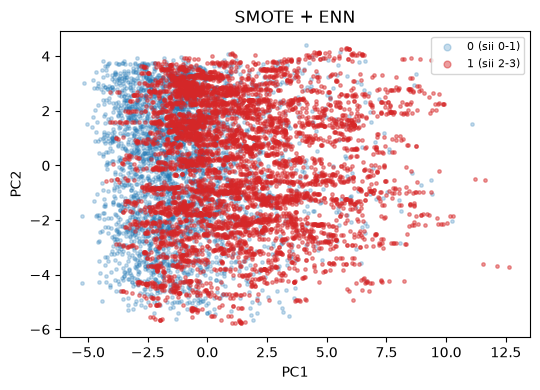

9047 record nel training set
              precision    recall  f1-score   support

           0      0.925     0.635     0.753      1484
           1      0.196     0.635     0.300       208

    accuracy                          0.635      1692
   macro avg      0.561     0.635     0.527      1692
weighted avg      0.836     0.635     0.698      1692



In [25]:
X_res, y_res = SMOTE(random_state=SEED).fit_resample(X_train, y_train)
X_res = fix_discrete(X_res, scaler)
print('dopo SMOTE: %s' % Counter(y_res))

X_res, y_res = EditedNearestNeighbours(sampling_strategy='all').fit_resample(X_res, y_res)
print('dopo ENN:   %s' % Counter(y_res))

plot_pca(X_res, y_res, 'SMOTE + ENN')
run_dt('SMOTE + ENN', X_res, y_res);

# Bilanciamento a livello di algoritmo: `class_weight`

`class_weight='balanced'` lascia i dati intatti e pesa ogni record in modo inversamente proporzionale alla
frequenza della sua classe: un errore sulla minoranza costa circa 7 volte un errore sulla maggioranza. Il peso
entra direttamente nel calcolo dell'impurità dell'albero, senza generare dati sintetici.

In [26]:
print('pesi:', {c: round(len(y_train) / (2 * n), 3) for c, n in sorted(Counter(y_train).items())})
run_dt('class_weight=balanced', X_train, y_train, class_weight='balanced');

pesi: {np.int64(0): 0.57, np.int64(1): 4.067}
              precision    recall  f1-score   support

           0      0.933     0.679     0.786      1484
           1      0.222     0.654     0.331       208

    accuracy                          0.676      1692
   macro avg      0.578     0.666     0.559      1692
weighted avg      0.846     0.676     0.730      1692



# Bilanciamento a livello di decisione: la soglia mobile

Il ri-campionamento agisce **sui dati**, `class_weight` **sulla funzione di costo**; la soglia mobile agisce
**sull'output**.

Un Decision Tree produce una probabilità (la frazione di positivi nella foglia) e `predict()` la confronta con la
soglia fissa 0.5. Quella soglia è ottimale solo se i due errori costano uguale. In generale, dato un costo
$C_{FP}$ per i falsi positivi e $C_{FN}$ per i falsi negativi, conviene predire 1 quando

$$p > \frac{C_{FP}}{C_{FP} + C_{FN}}$$

Con costi 1:7 (lo stesso rapporto che usa `class_weight='balanced'`) la soglia teorica è 1/8 = 0.125. Qui invece
la scegliamo empiricamente: probabilità out-of-fold sul training set con `cross_val_predict`, soglia che
massimizza F1 sulla minoranza, applicata poi al test. Il test non viene mai usato per scegliere la soglia.

In [27]:
clf_thr = DecisionTreeClassifier(random_state=SEED, **BEST)

# probabilità out-of-fold: ogni record è predetto da un modello che non lo ha visto
oof_prob = cross_val_predict(clf_thr, X_train, y_train,
                             cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                             method='predict_proba')[:, 1]

thresholds = np.linspace(0.02, 0.60, 120)


def best_threshold(y_true, prob):
    curve = []
    for t in thresholds:
        p, r, f, _ = precision_recall_fscore_support(y_true, (prob >= t).astype(int),
                                                     labels=[0, 1], zero_division=0)
        curve.append((p[1], r[1], f[1]))
    curve = np.array(curve)
    return thresholds[curve[:, 2].argmax()], curve


best_t, curve = best_threshold(y_train, oof_prob)
print('Soglia ottimale (F1 in CV sul train): %.3f' % best_t)
print('F1 in CV a quella soglia: %.3f   (a soglia 0.5: %.3f)'
      % (curve[:, 2].max(), curve[np.abs(thresholds - 0.5).argmin(), 2]))

Soglia ottimale (F1 in CV sul train): 0.147
F1 in CV a quella soglia: 0.302   (a soglia 0.5: 0.074)


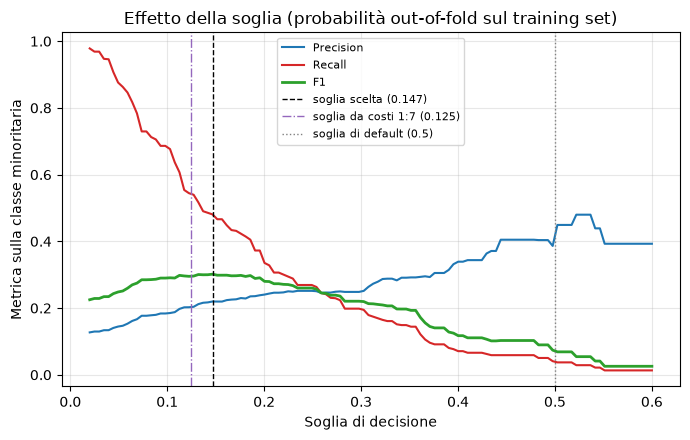

In [28]:
plt.figure(figsize=(7, 4.5))
plt.plot(thresholds, curve[:, 0], label='Precision', color='tab:blue')
plt.plot(thresholds, curve[:, 1], label='Recall', color='tab:red')
plt.plot(thresholds, curve[:, 2], label='F1', color='tab:green', lw=2)
plt.axvline(best_t, color='k', ls='--', lw=1, label='soglia scelta (%.3f)' % best_t)
plt.axvline(0.125, color='tab:purple', ls='-.', lw=1, label='soglia da costi 1:7 (0.125)')
plt.axvline(0.5, color='gray', ls=':', lw=1, label='soglia di default (0.5)')
plt.xlabel('Soglia di decisione')
plt.ylabel('Metrica sulla classe minoritaria')
plt.title('Effetto della soglia (probabilità out-of-fold sul training set)')
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
clf_thr.fit(X_train, y_train)
y_prob = clf_thr.predict_proba(X_test)[:, 1]

for t, lbl in [(0.5, 'soglia 0.5 (default)'), (best_t, 'soglia %.3f (ottimizzata)' % best_t)]:
    print('--- %s ---' % lbl)
    print(classification_report(y_test, (y_prob >= t).astype(int), digits=3))

probas['Soglia mobile'] = y_prob
add_result('Soglia mobile', (y_prob >= best_t).astype(int), y_prob)

--- soglia 0.5 (default) ---
              precision    recall  f1-score   support

           0      0.880     0.994     0.933      1484
           1      0.400     0.029     0.054       208

    accuracy                          0.875      1692
   macro avg      0.640     0.511     0.494      1692
weighted avg      0.821     0.875     0.825      1692

--- soglia 0.147 (ottimizzata) ---
              precision    recall  f1-score   support

           0      0.916     0.752     0.826      1484
           1      0.222     0.505     0.308       208

    accuracy                          0.722      1692
   macro avg      0.569     0.628     0.567      1692
weighted avg      0.830     0.722     0.762      1692



Il modello è **identico** alla baseline: stessi dati, stessi pesi, stesso albero. Cambia solo il punto in cui la
probabilità diventa classe, e le metriche sulla minoranza passano da inutilizzabili a competitive con le altre
tecniche. Per lo stesso motivo ROC-AUC e PR-AUC della soglia mobile coincidono con quelle della baseline: sono
calcolate su tutte le soglie possibili, quindi non vedono un cambio di soglia.

> La soglia qui massimizza F1, che pesa allo stesso modo falsi positivi e falsi negativi. In uno screening reale
> un falso negativo (un ragazzo non individuato) costa più di un falso positivo (un approfondimento non
> necessario), e la soglia andrebbe scelta dal rapporto tra i costi, probabilmente più bassa.

# Confronto complessivo

`Prec`, `Rec` e `F1` si riferiscono alla **classe minoritaria** (sii 2-3); `Spec` è il recall della classe 0.

In [30]:
res = pd.DataFrame(results).set_index('Metodo').round(3)
res.sort_values('F1', ascending=False)

,Prec,Rec,F1,Spec,MacroF1,BalAcc,ROC_AUC,PR_AUC
Metodo,,,,,,,,
class_weight=balanced,0.222,0.654,0.331,0.679,0.559,0.666,0.717,0.259
BorderlineSMOTE,0.272,0.399,0.324,0.850,0.601,0.625,0.668,0.227
Soglia mobile,0.222,0.505,0.308,0.752,0.567,0.628,0.696,0.227
RandomOverSampler,0.198,0.639,0.302,0.637,0.529,0.638,0.710,0.252
SMOTE + ENN,0.196,0.635,0.300,0.635,0.527,0.635,0.675,0.212
RandomUnderSampler,0.199,0.615,0.300,0.652,0.533,0.634,0.693,0.226
ADASYN,0.196,0.538,0.287,0.690,0.537,0.614,0.653,0.194
SMOTE,0.177,0.601,0.273,0.608,0.502,0.604,0.662,0.217
CondensedNearestNeighbour,0.247,0.279,0.262,0.881,0.575,0.580,0.670,0.209


La stessa tabella come heatmap: ogni colonna ha la propria scala di colore (dal minimo al massimo di quella
metrica), così si vede a colpo d'occhio dove ogni metodo è forte e dove paga.

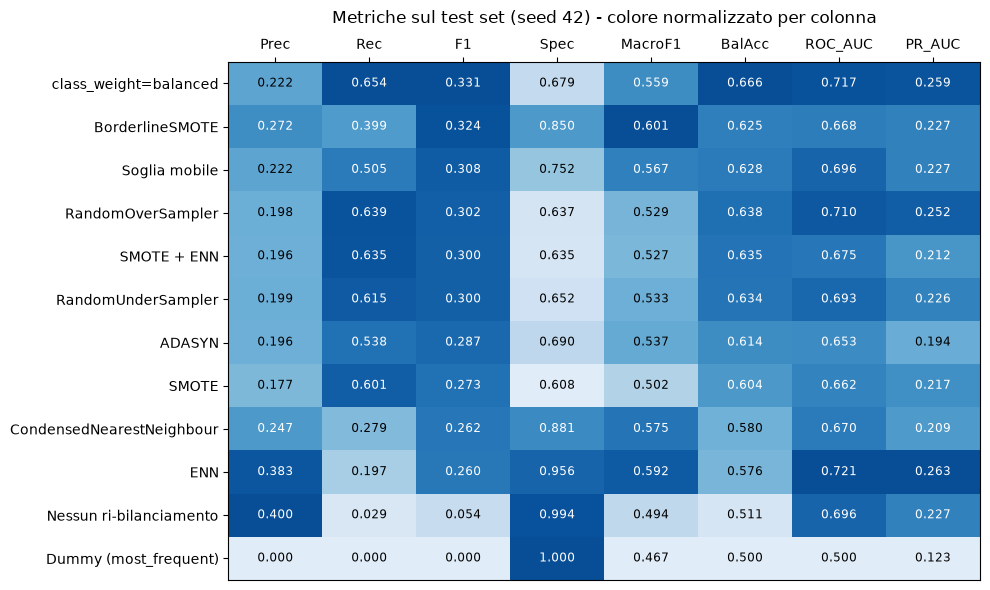

In [31]:
hm = res.sort_values('F1', ascending=False)
norm = (hm - hm.min()) / (hm.max() - hm.min())          # normalizzazione per colonna

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(norm.values, cmap='Blues', aspect='auto', vmin=-0.15, vmax=1.15)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, '%.3f' % hm.iat[i, j], ha='center', va='center', fontsize=8.5,
                color='white' if norm.iat[i, j] > 0.6 else 'black')
ax.set_xticks(range(hm.shape[1]))
ax.set_xticklabels(hm.columns)
ax.set_yticks(range(hm.shape[0]))
ax.set_yticklabels(hm.index)
ax.xaxis.tick_top()
ax.set_title('Metriche sul test set (seed 42) - colore normalizzato per colonna', pad=28)
plt.tight_layout()
plt.show()

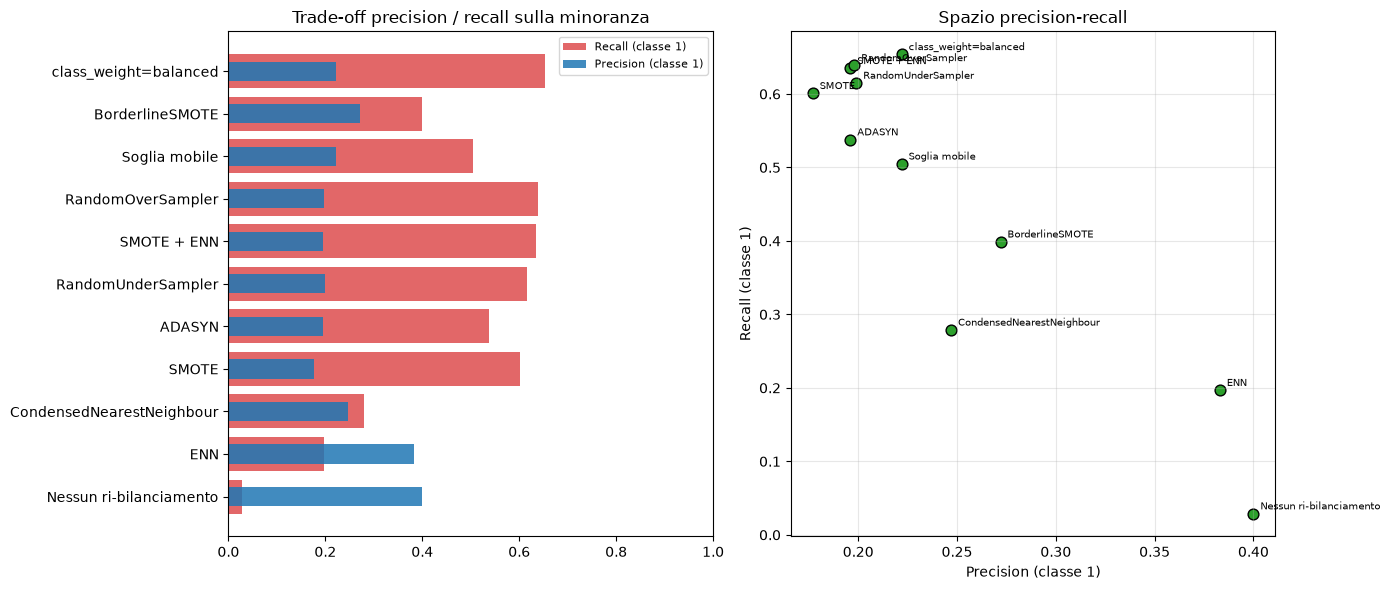

In [32]:
plot_df = res.drop(index=['Dummy (most_frequent)']).sort_values('F1')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(plot_df.index, plot_df['Rec'], color='tab:red', alpha=0.7, label='Recall (classe 1)')
axes[0].barh(plot_df.index, plot_df['Prec'], color='tab:blue', alpha=0.85, height=0.45,
             label='Precision (classe 1)')
axes[0].set_xlim(0, 1)
axes[0].set_title('Trade-off precision / recall sulla minoranza')
axes[0].legend(fontsize=8)

axes[1].scatter(plot_df['Prec'], plot_df['Rec'], s=60, c='tab:green', edgecolor='k')
for nm, r in plot_df.iterrows():
    axes[1].annotate(nm, (r['Prec'], r['Rec']), fontsize=7.5,
                     xytext=(5, 3), textcoords='offset points')
axes[1].set_xlabel('Precision (classe 1)')
axes[1].set_ylabel('Recall (classe 1)')
axes[1].set_title('Spazio precision-recall')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Curve ROC e Precision-Recall

La **ROC** misura la capacità di ranking indipendentemente dalla soglia; su dati sbilanciati tende a essere
ottimistica, perché il false positive rate ha al denominatore la classe maggioritaria. La curva
**Precision-Recall** è più informativa: il suo baseline casuale è la prevalenza della classe positiva (0.123).

Essendo il problema binario, la ROC one-vs-rest della classe 0 coincide con quella della classe 1, quindi ne
basta una per metodo. La soglia mobile non compare perché la sua curva coincide con quella della baseline.

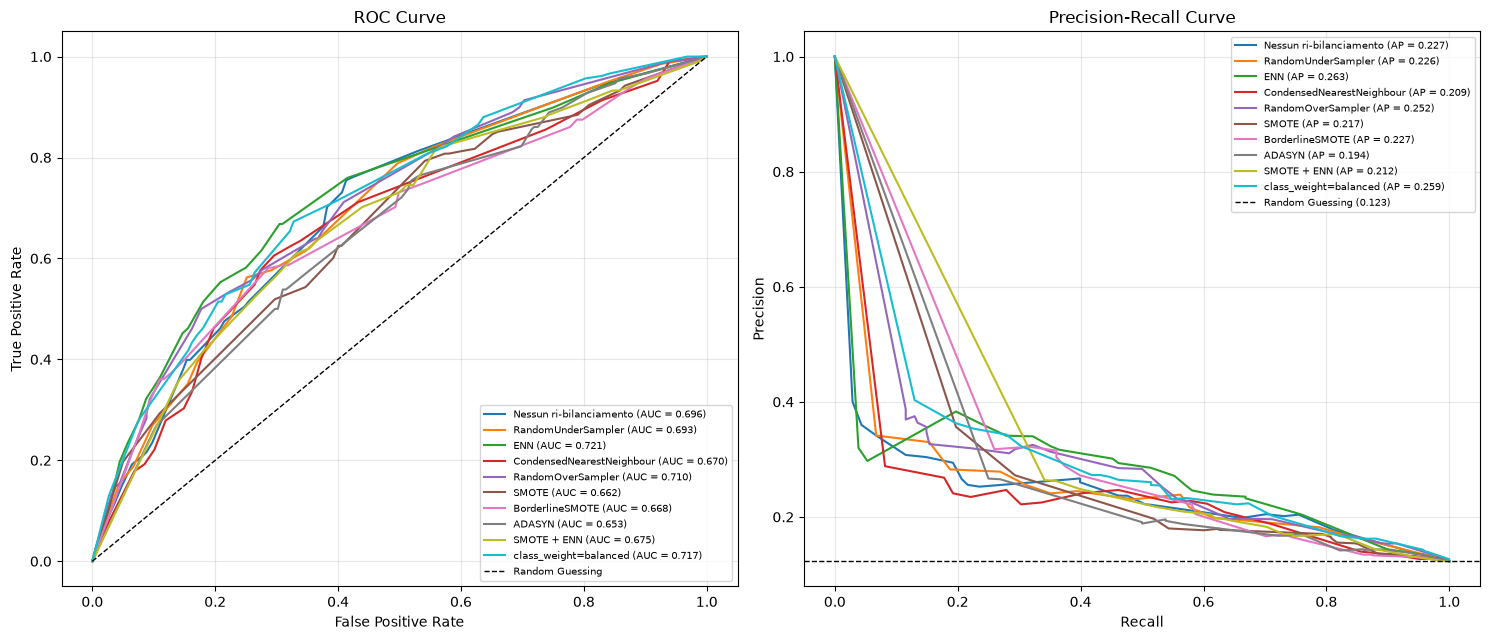

In [33]:
sel = [m for m in probas if m != 'Soglia mobile']

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

for nm in sel:
    p = probas[nm]
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, lw=1.5, label='%s (AUC = %.3f)' % (nm, roc_auc_score(y_test, p)))
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, lw=1.5, label='%s (AP = %.3f)' % (nm, average_precision_score(y_test, p)))

axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Random Guessing')
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve'); axes[0].legend(loc='lower right', fontsize=7.5); axes[0].grid(alpha=0.3)

axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1,
                label='Random Guessing (%.3f)' % y_test.mean())
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve'); axes[1].legend(loc='upper right', fontsize=7.5)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Stabilità dei risultati

Con 208 record di minoranza nel test, una differenza di 0.02 in F1 corrisponde a pochi record classificati
diversamente. Ripetiamo quindi l'intero esperimento (split, scaler, resampling, soglia) su 5 split diversi e
riportiamo media e deviazione standard: solo le differenze superiori alla deviazione standard sono interpretabili
come reali. Gli iperparametri dell'albero restano quelli trovati sopra; `CondensedNearestNeighbour` è escluso per
il costo computazionale.

In [34]:
def make_samplers(seed):
    return {
        'Nessun ri-bilanciamento': None,
        'RandomUnderSampler': RandomUnderSampler(random_state=seed),
        'ENN': EditedNearestNeighbours(),
        'RandomOverSampler': RandomOverSampler(random_state=seed),
        'SMOTE': SMOTE(random_state=seed),
        'BorderlineSMOTE': BorderlineSMOTE(random_state=seed),
        'ADASYN': ADASYN(random_state=seed),
        'SMOTE + ENN': [SMOTE(random_state=seed), EditedNearestNeighbours(sampling_strategy='all')],
        'class_weight=balanced': 'cw',
        'Soglia mobile': 'thr',
    }


rows = []
for seed in [0, 1, 2, 3, 4]:
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=df['sii'])
    sc = StandardScaler().fit(Xa)
    Xa, Xb = sc.transform(Xa), sc.transform(Xb)
    ya, yb = ya.values, yb.values

    for nm, samp in make_samplers(seed).items():
        cw, thr = None, 0.5
        Xr, yr = Xa, ya
        if samp == 'cw':
            cw = 'balanced'
        elif samp == 'thr':
            oof = cross_val_predict(DecisionTreeClassifier(random_state=seed, **BEST), Xa, ya,
                                    cv=StratifiedKFold(5, shuffle=True, random_state=seed),
                                    method='predict_proba')[:, 1]
            thr, _ = best_threshold(ya, oof)
        elif isinstance(samp, list):              # SMOTE, arrotondamento, poi ENN
            Xr, yr = samp[0].fit_resample(Xa, ya)
            Xr = fix_discrete(Xr, sc)
            Xr, yr = samp[1].fit_resample(Xr, yr)
        elif samp is not None:
            Xr, yr = samp.fit_resample(Xa, ya)
            if nm in ('SMOTE', 'BorderlineSMOTE', 'ADASYN'):
                Xr = fix_discrete(Xr, sc)

        clf = DecisionTreeClassifier(random_state=seed, class_weight=cw, **BEST).fit(Xr, yr)
        prob = clf.predict_proba(Xb)[:, 1]
        pred = (prob >= thr).astype(int) if samp == 'thr' else clf.predict(Xb)
        prec, rec, f1, _ = precision_recall_fscore_support(yb, pred, labels=[0, 1], zero_division=0)
        rows.append({'Metodo': nm, 'seed': seed, 'Prec': prec[1], 'Rec': rec[1], 'F1': f1[1],
                     'Spec': rec[0], 'ROC_AUC': roc_auc_score(yb, prob),
                     'PR_AUC': average_precision_score(yb, prob)})

stab = pd.DataFrame(rows)
agg = stab.groupby('Metodo')[['F1', 'Rec', 'Prec', 'Spec', 'ROC_AUC', 'PR_AUC']].agg(['mean', 'std'])
agg = agg.round(3).sort_values(('F1', 'mean'), ascending=False)
agg

F1           Rec          Prec          Spec  \
                          mean    std   mean    std   mean    std   mean   
Metodo                                                                     
Soglia mobile            0.312  0.014  0.501  0.037  0.228  0.020  0.759   
class_weight=balanced    0.305  0.018  0.612  0.035  0.204  0.016  0.663   
RandomOverSampler        0.300  0.011  0.617  0.075  0.200  0.016  0.648   
RandomUnderSampler       0.293  0.019  0.583  0.059  0.196  0.014  0.664   
SMOTE + ENN              0.284  0.018  0.725  0.039  0.177  0.014  0.523   
BorderlineSMOTE          0.284  0.011  0.403  0.034  0.221  0.011  0.800   
ADASYN                   0.271  0.016  0.377  0.040  0.213  0.018  0.803   
SMOTE                    0.266  0.025  0.402  0.083  0.206  0.035  0.771   
ENN                      0.177  0.033  0.129  0.036  0.304  0.072  0.956   
Nessun ri-bilanciamento  0.037  0.023  0.020  0.013  0.205  0.122  0.992   

                               ROC_AUC        PR_AUC         
                           std    mean    std   mean    std  
Metodo                                                       
Soglia mobile            0.040   0.682  0.015  0.223  0.014  
class_weight=balanced    0.041   0.678  0.022  0.229  0.025  
RandomOverSampler        0.075   0.673  0.018  0.211  0.014  
RandomUnderSampler       0.040   0.665  0.017  0.210  0.009  
SMOTE + ENN              0.059   0.663  0.011  0.196  0.007  
BorderlineSMOTE          0.025   0.657  0.008  0.201  0.008  
ADASYN                   0.034   0.647  0.016  0.186  0.005  
SMOTE                    0.083   0.635  0.021  0.180  0.010  
ENN                      0.017   0.687  0.018  0.224  0.021  
Nessun ri-bilanciamento  0.005   0.682  0.015  0.223  0.014

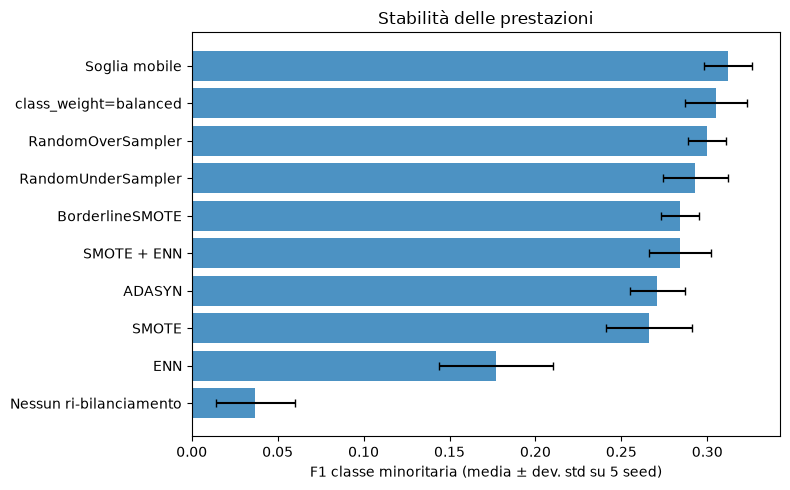

In [35]:
o = agg.sort_values(('F1', 'mean'))
plt.figure(figsize=(8, 5))
plt.barh(o.index, o[('F1', 'mean')], xerr=o[('F1', 'std')],
         color='tab:blue', alpha=0.8, capsize=3)
plt.xlabel('F1 classe minoritaria (media ± dev. std su 5 seed)')
plt.title('Stabilità delle prestazioni')
plt.tight_layout()
plt.show()

ROC-AUC e PR-AUC per metodo, con media e deviazione standard sui 5 seed. La linea tratteggiata è la baseline
senza ri-bilanciamento: un metodo migliora davvero il potere discriminante solo se la sua barra d'errore resta
interamente a destra della linea.

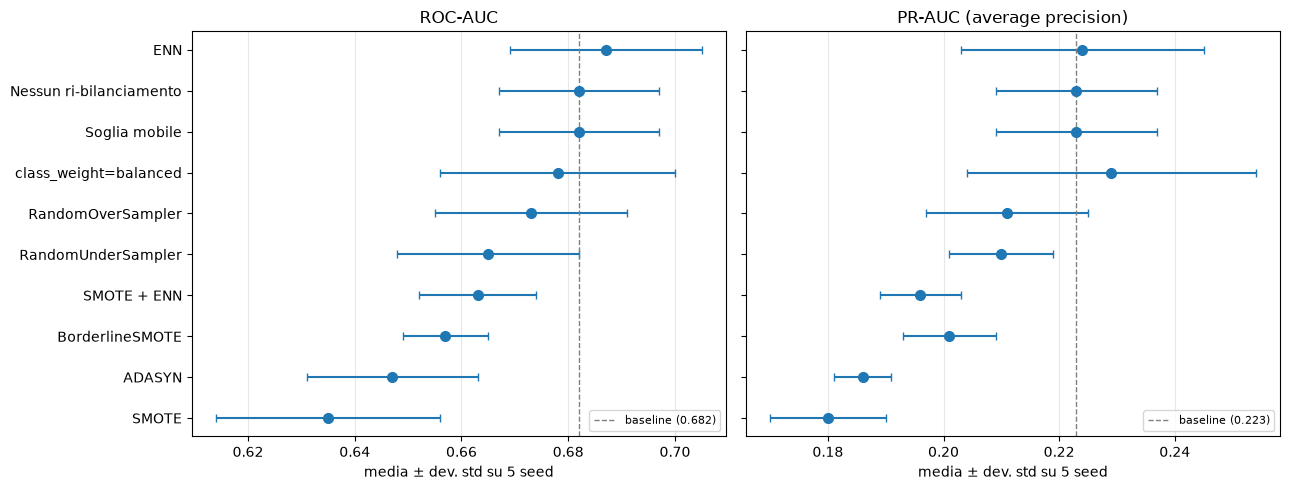

In [36]:
o = agg.sort_values(('ROC_AUC', 'mean'))
base = agg.loc['Nessun ri-bilanciamento']

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, m, ttl in [(axes[0], 'ROC_AUC', 'ROC-AUC'), (axes[1], 'PR_AUC', 'PR-AUC (average precision)')]:
    ax.errorbar(o[(m, 'mean')], range(len(o)), xerr=o[(m, 'std')], fmt='o', ms=7,
                color='tab:blue', ecolor='tab:blue', elinewidth=1.5, capsize=3)
    ax.axvline(base[(m, 'mean')], color='gray', ls='--', lw=1,
               label='baseline (%.3f)' % base[(m, 'mean')])
    ax.set_title(ttl)
    ax.set_xlabel('media ± dev. std su 5 seed')
    ax.grid(axis='x', alpha=0.3)
    ax.legend(fontsize=8, loc='lower right')
axes[0].set_yticks(range(len(o)))
axes[0].set_yticklabels(o.index)
plt.tight_layout()
plt.show()

# Conclusioni

1. **Senza ri-bilanciamento il modello è inutilizzabile.** Ha un ROC-AUC discreto (0.68 in media sui 5 seed),
   quindi ordina i record in modo sensato, ma alla soglia 0.5 predice quasi sempre la maggioranza: recall sulla
   minoranza 0.02, F1 0.04. L'accuracy resta all'87%, la stessa del Dummy: è la metrica sbagliata.

2. **Tutte le tecniche alzano il recall a scapito della precision.** Nei metodi che bilanciano le classi il
   recall passa da 0.02 a 0.38–0.73, la precision scende a 0.18–0.23 e F1 sale fino a circa 0.30 (medie sui 5
   seed). In uno screening il trade-off è favorevole: un ragazzo con uso problematico non individuato costa più di
   un approfondimento non necessario.

3. **Le tecniche migliori non sono distinguibili tra loro.** Sui 5 seed il gruppo di testa è soglia mobile
   (F1 0.312 ± 0.014), `class_weight` (0.305 ± 0.018), RandomOverSampler (0.300 ± 0.011) e RandomUnderSampler
   (0.293 ± 0.019): le differenze sono dentro una deviazione standard. Il singolo split lo conferma: BorderlineSMOTE
   è secondo sul seed 42 (0.324) ma solo a metà classifica in media (0.284).

4. **L'oversampling sintetico non batte quello casuale.** SMOTE, BorderlineSMOTE, ADASYN e SMOTE + ENN restano
   tra 0.27 e 0.28 di F1, sotto ROS e RUS, e abbassano ROC-AUC e PR-AUC rispetto alla baseline. Su questo dataset
   ha inoltre un problema specifico: le colonne discrete (`Sex`, `hoursday`, le one-hot) vanno arrotondate,
   altrimenti l'albero impara a riconoscere i record sintetici; SMOTENC risolve i valori frazionari ma altera le
   distribuzioni (maschi dal 70% all'84% nei sintetici).

5. **Le tecniche di cleaning e il metodo combinato si collocano agli estremi.** ENN e CNN tolgono solo la
   maggioranza vicina alla frontiera: recall moderato e specificità alta (ENN 0.13 e 0.96 in media, CNN 0.28 e
   0.88 sul seed 42). SMOTE + ENN ha
   il recall più alto (0.73 in media) ma anche la specificità più bassa (0.52).

6. **Nessuna tecnica migliora il potere discriminante.** La baseline ha ROC-AUC 0.682 e PR-AUC 0.223 in media;
   nessuna tecnica la supera oltre la deviazione standard (ENN 0.687 di ROC-AUC e `class_weight` 0.229 di PR-AUC
   sono dentro il rumore) e i metodi sintetici la abbassano. Le tecniche spostano il punto operativo del classificatore, non la curva su cui si
   muove.

7. **La soglia mobile lo dimostra direttamente.** Usa esattamente l'albero della baseline e cambia solo la soglia
   (0.147, vicina allo 0.125 ricavato da costi 1:7): ottiene l'F1 medio più alto con una delle deviazioni standard
   più basse. Ri-campionare, ri-pesare e ri-tagliare convergono sullo stesso risultato perché regolano la stessa
   cosa.

8. **Implicazione pratica.** Con questo dataset e un Decision Tree, generare dati sintetici non è giustificato:
   `class_weight='balanced'` o una soglia scelta in base ai costi danno lo stesso risultato senza alterare i dati
   e senza costo computazionale. Il ri-campionamento resta utile con classificatori che non espongono pesi di
   classe né probabilità.